style et données

In [1]:
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Couleurs : bleu = score pondéré / résultat final, orange = moyenne simple, textes en gris foncé
BLEU, BLEU_CLAIR, ORANGE, GRIS, NOIR = "#2a78d6", "#b7d3f6", "#eb6834", "#52514e", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": GRIS, "axes.labelcolor": GRIS,
                     "xtick.color": GRIS, "ytick.color": GRIS, "text.color": NOIR,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
                     "axes.axisbelow": True})

# Résultats produits par Hive et Spark (petits fichiers du dossier results/)
COLONNES = ["rang", "movieId", "title", "nb_notes", "note_moyenne", "score_pondere"]
top10 = pd.read_csv("../results/top10_hive.tsv", sep="\t", names=COLONNES, quoting=csv.QUOTE_NONE)
temps = pd.concat([pd.read_csv("../results/temps_hive.csv"), pd.read_csv("../results/temps_spark.csv")])
stats = pd.read_csv("../results/stats_par_film.tsv", sep="\t")
stats.columns = ["movieId", "nb_notes", "note_moyenne"]
print(top10.shape, temps.shape, stats.shape)   # attendu : (10, 6) (6, 3) (83239, 3)

(10, 6) (6, 3) (83239, 3)


le top 10 (figure principale)

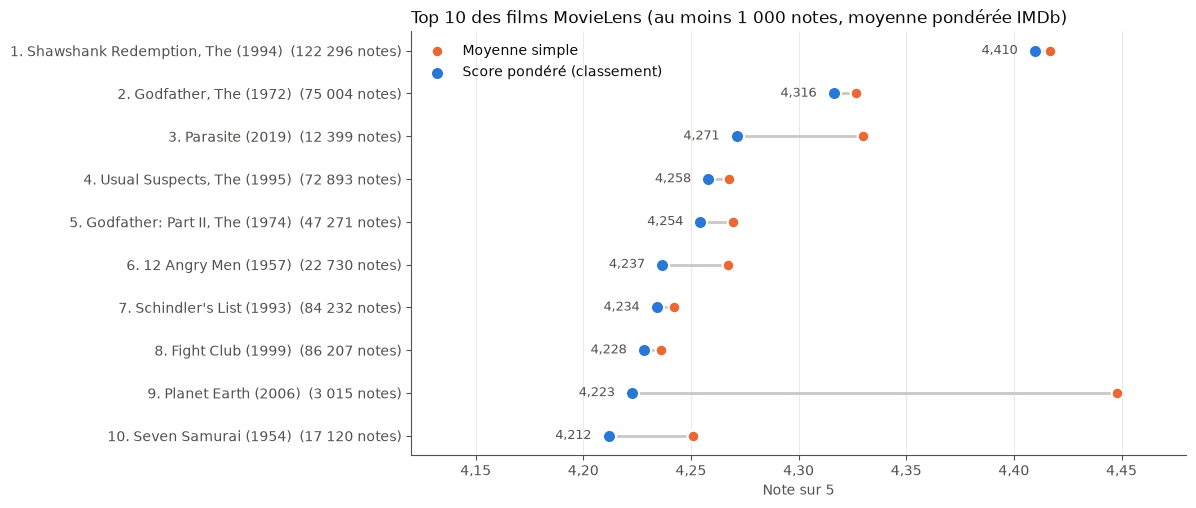

In [2]:
# Titre court : on enlève le titre original entre parenthèses (ex. "Shichinin no samurai")
top10["film"] = top10["title"].str.replace(r" \((?!\d{4}\))[^)]*\)", "", regex=True)
top10["etiquette"] = (top10["rang"].astype(str) + ". " + top10["film"] + "  ("
                      + top10["nb_notes"].map("{:,}".format).str.replace(",", " ") + " notes)")

fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(top10))[::-1]   # le n°1 en haut
# trait gris entre la moyenne simple et le score pondéré : c'est l'effet de la pondération
ax.hlines(y, top10["score_pondere"], top10["note_moyenne"], color="#c9c8c3", linewidth=2, zorder=1)
ax.scatter(top10["note_moyenne"], y, s=70, color=ORANGE, edgecolor="white", linewidth=1.5, zorder=2, label="Moyenne simple")
ax.scatter(top10["score_pondere"], y, s=90, color=BLEU, edgecolor="white", linewidth=1.5, zorder=3, label="Score pondéré (classement)")
for yi, s in zip(y, top10["score_pondere"]):
    ax.text(s - 0.008, yi, f"{s:.3f}".replace(".", ","), ha="right", va="center", fontsize=9, color=GRIS)
ax.set_yticks(y)
ax.set_yticklabels(top10["etiquette"])
ax.set_xlim(4.12, 4.48)
ax.xaxis.set_major_formatter(lambda v, pos: f"{v:.2f}".replace(".", ","))
ax.set_xlabel("Note sur 5")
ax.grid(axis="y", visible=False)
ax.set_title("Top 10 des films MovieLens (au moins 1 000 notes, moyenne pondérée IMDb)", loc="left", fontsize=12)
ax.legend(loc="upper left", frameon=False)
fig.savefig("../figures/top10_films.png", dpi=150, bbox_inches="tight")
plt.show()

comparaison des temps

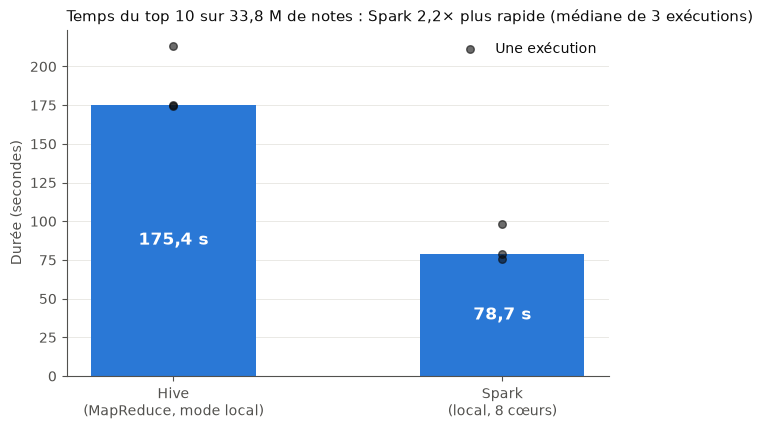

In [3]:
# Barre = médiane des 3 exécutions, points = chaque exécution
mediane = temps.groupby("outil")["duree_s"].median().reindex(["hive", "spark"])
noms = ["Hive\n(MapReduce, mode local)", "Spark\n(local, 8 cœurs)"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(noms, mediane.values, width=0.5, color=BLEU, zorder=1)
for i, outil in enumerate(["hive", "spark"]):
    valeurs = temps.loc[temps["outil"] == outil, "duree_s"]
    ax.scatter([i] * len(valeurs), valeurs, s=30, color=NOIR, alpha=0.6, zorder=2,
               label="Une exécution" if i == 0 else None)
    ax.text(i, mediane[outil] / 2, f"{mediane[outil]:.1f} s".replace(".", ","),
            ha="center", va="center", color="white", fontsize=12, fontweight="bold")
rapport = f"{mediane['hive'] / mediane['spark']:.1f}".replace(".", ",")
ax.set_ylabel("Durée (secondes)")
ax.grid(axis="x", visible=False)
ax.set_title(f"Temps du top 10 sur 33,8 M de notes : Spark {rapport}× plus rapide (médiane de 3 exécutions)",
             loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper right")
fig.savefig("../figures/comparaison_temps.png", dpi=150, bbox_inches="tight")
plt.show()

distribution et seuil retenu

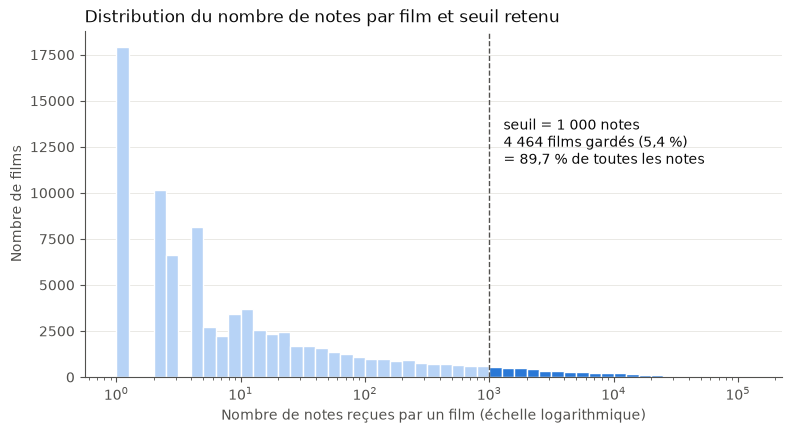

In [4]:
# Films gardés par le seuil : en bleu foncé, à droite de la ligne pointillée
SEUIL = 1000
gardes = stats[stats["nb_notes"] >= SEUIL]
pct_films = 100 * len(gardes) / len(stats)
pct_notes = 100 * gardes["nb_notes"].sum() / stats["nb_notes"].sum()

bornes = np.logspace(0, 5.1, 52)   # classes de largeur 10^0,1 : 1 000 tombe pile sur une limite
fig, ax = plt.subplots(figsize=(9, 4.5))
n, b, barres = ax.hist(stats["nb_notes"], bins=bornes, color=BLEU_CLAIR, edgecolor="white", linewidth=1)
for barre, gauche in zip(barres, b[:-1]):
    if gauche >= SEUIL * 0.999:   # petite marge pour les arrondis
        barre.set_facecolor(BLEU)
ax.axvline(SEUIL, color=GRIS, linestyle="--", linewidth=1)
texte = (f"seuil = 1 000 notes\n{len(gardes):,} films gardés ({pct_films:.1f} %)\n"
         f"= {pct_notes:.1f} % de toutes les notes").replace(",", " ").replace(".", ",")
ax.text(SEUIL * 1.3, ax.get_ylim()[1] * 0.75, texte, color=NOIR, fontsize=10, va="top")
ax.set_xscale("log")
ax.set_xlabel("Nombre de notes reçues par un film (échelle logarithmique)")
ax.set_ylabel("Nombre de films")
ax.grid(axis="x", visible=False)
ax.set_title("Distribution du nombre de notes par film et seuil retenu", loc="left")
fig.savefig("../figures/distribution_seuil.png", dpi=150, bbox_inches="tight")
plt.show()